# COMP472 Project – k-Nearest Neighbours (from scratch)

k-NN written by us with NumPy only (no `sklearn.neighbors`), tested on both tasks:

* **Image** – 50 classes, 500 features
* **Sentiment** – 3 classes, 768 features

How k-NN works: to classify a new example, find the **k training examples closest to it** and let them **vote**. There is no training step: the "model" is the training set itself.

Plan

1. Load the data and split it (same 80/20 split as the rest of the team, from `common.py`)
2. Distance functions: Euclidean, Manhattan, cosine
3. Finding the neighbours and voting
4. The `KNNClassifier` class
5. Image experiments: k, distance, normalisation, weighted voting, train vs validation
6. Sentiment experiments: the same
7. Best models: confusion matrix and error analysis
8. Final predictions on the test set + Kaggle file

**Running time on a laptop:** about 10–15 minutes in total (Manhattan distance is the slow part).

## 0. Imports

In [3]:
import os
import sys

# This notebook is in a sub-folder. Work from the project root: the folder
# that contains common.py, Project_info/, results/ and predictions/.
if not os.path.exists("common.py"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common   # shared team file: loading, split, preprocessing, metrics

os.makedirs("results/knn", exist_ok=True)
os.makedirs("predictions", exist_ok=True)

## 1. Load and split the data

In [4]:
X_image, y_image, X_image_test, image_test_ids = common.load_task("image")
X_sent, y_sent, X_sent_test, sent_test_ids = common.load_task("sentiment")
print("Image     train:", X_image.shape, " test:", X_image_test.shape)
print("Sentiment train:", X_sent.shape, " test:", X_sent_test.shape)


def prepare(X, y, mode):
    # 80 / 20 split (same rows as every other model of the team)
    train_idx, val_idx = common.stratified_split(y)
    # preprocessing statistics come from the TRAINING rows only
    stats = common.fit_preprocessing(X[train_idx], mode)
    X_train = common.apply_preprocessing(X[train_idx], mode, stats)
    X_val = common.apply_preprocessing(X[val_idx], mode, stats)
    return X_train, y[train_idx], X_val, y[val_idx]

Image     train: (20000, 500)  test: (5000, 500)
Sentiment train: (12000, 768)  test: (5000, 768)


## 2. Distance functions

For two examples **a** and **b** with d features:

| distance | formula | idea |
|---|---|---|
| Euclidean | $\sqrt{\sum_i (a_i-b_i)^2}$ | straight-line distance |
| Manhattan | $\sum_i \lvert a_i-b_i \rvert$ | sum of the differences, less sensitive to one big difference |
| Cosine | $1 - \dfrac{a \cdot b}{\lVert a\rVert \, \lVert b\rVert}$ | only the **direction** of the vectors counts, not their length |

First a simple version for **one pair** of examples, so the formulas are easy to read.

In [5]:
def euclidean_one(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan_one(a, b):
    return np.sum(np.abs(a - b))

def cosine_one(a, b):
    return 1 - np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)

Computing these one pair at a time would be far too slow (4,000 validation × 16,000 training examples = 64 million pairs). So we compute a whole **block** of distances at once: `distances(A, B)` returns a matrix where row *i*, column *j* is the distance between `A[i]` and `B[j]`.

* Euclidean uses the identity $\lVert a-b\rVert^2 = \lVert a\rVert^2 - 2\,a\cdot b + \lVert b\rVert^2$, so the main work is one matrix product `A @ B.T`.
* Manhattan has no such trick, so we loop over the rows of A (slower).
* Cosine: normalise every row to length 1, then the dot products give the cosine similarities.

In [6]:
def euclidean_distances(A, B):
    squared = (A ** 2).sum(axis=1)[:, None] - 2 * A @ B.T + (B ** 2).sum(axis=1)[None, :]
    return np.sqrt(np.maximum(squared, 0))      # max(.,0): tiny negative values from rounding


def manhattan_distances(A, B):
    D = np.zeros((len(A), len(B)), dtype=np.float32)
    for i in range(len(A)):
        D[i] = np.abs(B - A[i]).sum(axis=1)     # distance from A[i] to every row of B
    return D


def cosine_distances(A, B):
    A_unit = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    B_unit = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return 1 - A_unit @ B_unit.T


DISTANCES = {
    "euclidean": euclidean_distances,
    "manhattan": manhattan_distances,
    "cosine": cosine_distances,
}

# Check: the fast versions give the same numbers as the simple ones
a, b = X_sent[0], X_sent[1]
print("euclidean:", euclidean_one(a, b), euclidean_distances(a[None], b[None])[0, 0])
print("manhattan:", manhattan_one(a, b), manhattan_distances(a[None], b[None])[0, 0])
print("cosine:   ", cosine_one(a, b), cosine_distances(a[None], b[None])[0, 0])

euclidean: 7.73391 7.7339106
manhattan: 173.01064 173.01064
cosine:    0.3279422 0.32794225


## 3. Finding the neighbours and voting

**Step 1 – neighbours.** For every query example: compute its distance to all training examples, sort, keep the `max_k` closest. We do it in chunks of 500 queries so the distance matrix fits in memory.

**Step 2 – vote.** Each of the k nearest neighbours votes for its class.

* **Uniform voting:** every neighbour has 1 vote.
* **Distance-weighted voting:** a neighbour at distance d gives $1 / d^{\,p}$ votes, so closer neighbours count more. A bigger `power` p makes the closest neighbours count much more than the far ones.

If two classes get the same number of votes, `np.argmax` picks the smaller class number.

**Trick for the experiments:** the 50 nearest neighbours already contain the 1, 3, 5, … nearest ones. So we find the neighbours **once** and then try every k (and every voting rule) on the same list. This makes the experiments much faster without changing the results.

In [7]:
def find_neighbors(X_train, X_query, distance_name, max_k, chunk_size=500):
    distance_function = DISTANCES[distance_name]
    all_indices = []
    all_distances = []
    for start in range(0, len(X_query), chunk_size):
        D = distance_function(X_query[start:start + chunk_size], X_train)
        nearest = np.argsort(D, axis=1)[:, :max_k]              # column numbers of the max_k smallest
        all_indices.append(nearest)
        all_distances.append(np.take_along_axis(D, nearest, axis=1))
    return np.vstack(all_indices), np.vstack(all_distances)


def vote(neighbor_indices, neighbor_distances, y_train, k, n_classes,
         weighting="uniform", power=1):
    predictions = np.zeros(len(neighbor_indices), dtype=int)
    for i in range(len(neighbor_indices)):
        votes = np.zeros(n_classes)
        for j in range(k):                                     # the k closest neighbours
            label = y_train[neighbor_indices[i, j]]
            if weighting == "uniform":
                votes[label] += 1
            else:                                              # "distance"
                votes[label] += 1 / (neighbor_distances[i, j] + 1e-8) ** power
        predictions[i] = np.argmax(votes)
    return predictions

## 4. The `KNNClassifier` class

The same two steps packed into a class with `fit` and `predict`, like a normal classifier. `fit` only stores the training data — that is all the "training" k-NN needs.

In [8]:
class KNNClassifier:
    def __init__(self, k=5, distance="euclidean", weighting="uniform", power=1):
        self.k = k
        self.distance = distance
        self.weighting = weighting
        self.power = power

    def fit(self, X_train, y_train):
        self.X_train = X_train
        self.y_train = y_train
        self.n_classes = int(y_train.max()) + 1
        return self

    def predict(self, X):
        indices, distances = find_neighbors(self.X_train, X, self.distance, self.k)
        return vote(indices, distances, self.y_train, self.k, self.n_classes,
                    self.weighting, self.power)


# Small check on 300 sentiment validation examples
X_tr, y_tr, X_va, y_va = prepare(X_sent, y_sent, "standardize")
knn = KNNClassifier(k=5, distance="euclidean").fit(X_tr, y_tr)
print("accuracy on 300 validation examples:", common.accuracy(y_va[:300], knn.predict(X_va[:300])))

accuracy on 300 validation examples: 0.5166666666666667


### Experiment helper

`try_settings` prepares the data, finds the neighbours once, then measures validation accuracy for every k. Every result is stored in `all_results` and saved to a CSV at the end of each task.

In [9]:
all_results = []
neighbor_cache = {}      # (task, preprocess, distance, max k) -> neighbours, so we never compute them twice


def try_settings(task, X, y, preprocess, distance, ks, weighting="uniform", power=1):
    n_classes = common.N_CLASSES[task]
    X_tr, y_tr, X_va, y_va = prepare(X, y, preprocess)

    key = (task, preprocess, distance, max(ks))
    if key not in neighbor_cache:
        start = time.time()
        indices, distances = find_neighbors(X_tr, X_va, distance, max(ks))
        neighbor_cache[key] = (indices, distances, time.time() - start)
    indices, distances, seconds = neighbor_cache[key]

    accuracies = []
    for k in ks:
        y_pred = vote(indices, distances, y_tr, k, n_classes, weighting, power)
        acc = common.accuracy(y_va, y_pred)
        accuracies.append(acc)
        all_results.append({
            "task": task, "preprocess": preprocess, "distance": distance,
            "weighting": weighting if weighting == "uniform" else f"1/d^{power}",
            "k": k, "val_acc": round(acc, 4), "neighbour_search_seconds": round(seconds, 1),
        })
    label = f"{preprocess}, {distance}, " + (weighting if weighting == "uniform" else f"1/d^{power}")
    print(f"{label:<40} " + "  ".join(f"k={k}: {a:.3f}" for k, a in zip(ks, accuracies)))
    return accuracies


def plot_k_curves(ks, curves, title):
    plt.figure(figsize=(7, 4))
    for label, accuracies in curves.items():
        plt.plot(ks, accuracies, marker="o", label=label)
    plt.xscale("log")
    plt.xticks(ks, [str(k) for k in ks])
    plt.xlabel("k (number of neighbours)")
    plt.ylabel("validation accuracy")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.show()

## 5. Image task

Facts about the image features (from our data exploration):

* every value is ≥ 0 and about **85% of the values are 0** (it looks like a histogram of visual words),
* every row already has **length 1**. For vectors of length 1, $\lVert a-b\rVert^2 = 2 - 2\cos(a,b)$, so **Euclidean and cosine give exactly the same neighbours** on the raw features. Expect identical results for those two.

### 5.1 Effect of k and of the distance (raw features, uniform voting)

none, euclidean, uniform                 k=1: 0.519  k=3: 0.425  k=5: 0.424  k=10: 0.393  k=20: 0.359  k=50: 0.307
none, manhattan, uniform                 k=1: 0.405  k=3: 0.319  k=5: 0.280  k=10: 0.245  k=20: 0.207  k=50: 0.167
none, cosine, uniform                    k=1: 0.519  k=3: 0.424  k=5: 0.423  k=10: 0.393  k=20: 0.359  k=50: 0.306


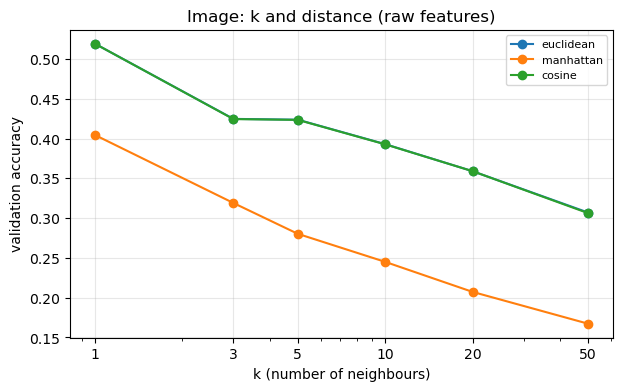

In [10]:
IMAGE_KS = [1, 3, 5, 10, 20, 50]

curves = {}
for distance in ["euclidean", "manhattan", "cosine"]:
    curves[distance] = try_settings("image", X_image, y_image, "none", distance, IMAGE_KS)
plot_k_curves(IMAGE_KS, curves, "Image: k and distance (raw features)")

### 5.2 Effect of normalisation

* `standardize`: every feature gets mean 0 and std 1.
* `sqrt`: square root of every value, then each row back to length 1. Large values shrink, so a few big counts no longer dominate the distance.

none, euclidean, uniform                 k=1: 0.519  k=3: 0.425  k=5: 0.424  k=10: 0.393  k=20: 0.359  k=50: 0.307
none, cosine, uniform                    k=1: 0.519  k=3: 0.424  k=5: 0.423  k=10: 0.393  k=20: 0.359  k=50: 0.306
standardize, euclidean, uniform          k=1: 0.430  k=3: 0.350  k=5: 0.330  k=10: 0.302  k=20: 0.261  k=50: 0.217
standardize, cosine, uniform             k=1: 0.533  k=3: 0.421  k=5: 0.421  k=10: 0.396  k=20: 0.379  k=50: 0.334
sqrt, euclidean, uniform                 k=1: 0.563  k=3: 0.464  k=5: 0.454  k=10: 0.434  k=20: 0.388  k=50: 0.333
sqrt, cosine, uniform                    k=1: 0.563  k=3: 0.464  k=5: 0.454  k=10: 0.434  k=20: 0.388  k=50: 0.333


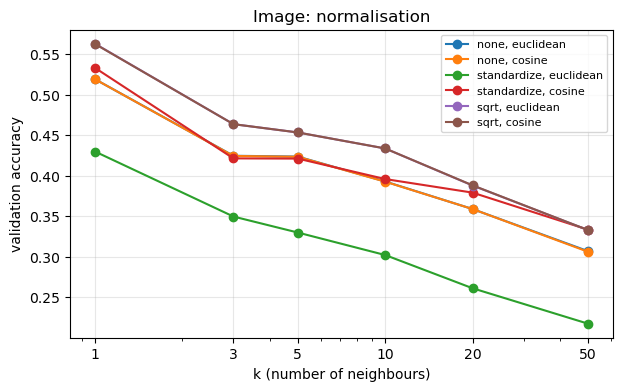

In [11]:
curves = {}
for preprocess in ["none", "standardize", "sqrt"]:
    for distance in ["euclidean", "cosine"]:
        curves[f"{preprocess}, {distance}"] = try_settings("image", X_image, y_image,
                                                           preprocess, distance, IMAGE_KS)
plot_k_curves(IMAGE_KS, curves, "Image: normalisation")

### 5.3 Uniform vs distance-weighted voting

Using the best normalisation and distance from 5.2 (change them here if your results differ).

sqrt, cosine, uniform                    k=1: 0.563  k=3: 0.464  k=5: 0.454  k=10: 0.434  k=20: 0.388  k=50: 0.333
sqrt, cosine, 1/d^1                      k=1: 0.563  k=3: 0.555  k=5: 0.535  k=10: 0.491  k=20: 0.453  k=50: 0.378
sqrt, cosine, 1/d^2                      k=1: 0.563  k=3: 0.557  k=5: 0.541  k=10: 0.500  k=20: 0.469  k=50: 0.405
sqrt, cosine, 1/d^4                      k=1: 0.563  k=3: 0.561  k=5: 0.553  k=10: 0.533  k=20: 0.513  k=50: 0.468
sqrt, cosine, 1/d^8                      k=1: 0.563  k=3: 0.567  k=5: 0.569  k=10: 0.564  k=20: 0.560  k=50: 0.544


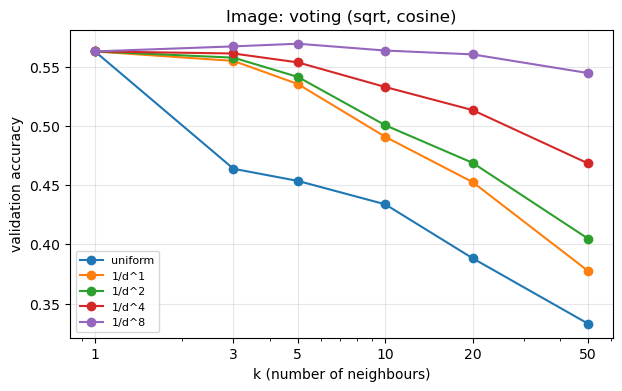

In [12]:
IMAGE_PREPROCESS = "sqrt"
IMAGE_DISTANCE = "cosine"

curves = {"uniform": try_settings("image", X_image, y_image, IMAGE_PREPROCESS, IMAGE_DISTANCE, IMAGE_KS)}
for power in [1, 2, 4, 8]:
    curves[f"1/d^{power}"] = try_settings("image", X_image, y_image, IMAGE_PREPROCESS, IMAGE_DISTANCE,
                                         IMAGE_KS, weighting="distance", power=power)
plot_k_curves(IMAGE_KS, curves, f"Image: voting ({IMAGE_PREPROCESS}, {IMAGE_DISTANCE})")

pd.DataFrame([r for r in all_results if r["task"] == "image"]).to_csv(
    "results/knn/image_experiments.csv", index=False)

### 5.4 Training vs validation accuracy (overfitting / underfitting)

We predict 2,000 **training** examples with the training set itself. With k = 1 the nearest neighbour of a training example is the example itself, so training accuracy is 100% — k = 1 memorises the training data. With a large k the model averages over many neighbours and becomes too simple. The best k is the one with the highest **validation** accuracy.

k =   1   train 1.000   validation 0.563
k =   3   train 0.759   validation 0.464
k =   5   train 0.716   validation 0.454
k =  10   train 0.640   validation 0.434
k =  20   train 0.555   validation 0.388
k =  50   train 0.449   validation 0.333


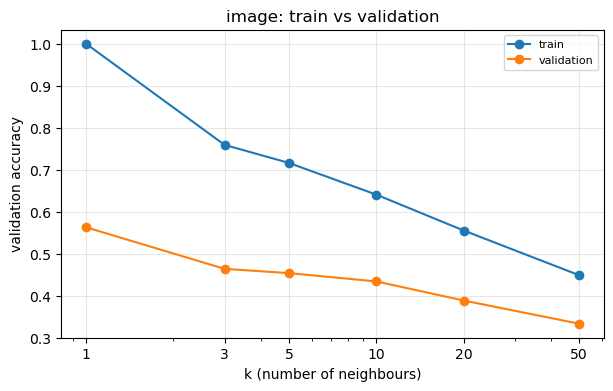

In [13]:
def train_vs_validation(task, X, y, preprocess, distance, ks, weighting="uniform", power=1, n_train_check=2000):
    n_classes = common.N_CLASSES[task]
    X_tr, y_tr, X_va, y_va = prepare(X, y, preprocess)
    rng = np.random.default_rng(42)
    check = rng.choice(len(X_tr), min(n_train_check, len(X_tr)), replace=False)   # 2000 random training rows

    train_idx, train_dist = find_neighbors(X_tr, X_tr[check], distance, max(ks))
    val_idx, val_dist = find_neighbors(X_tr, X_va, distance, max(ks))
    train_acc, val_acc = [], []
    for k in ks:
        train_acc.append(common.accuracy(y_tr[check], vote(train_idx, train_dist, y_tr, k, n_classes, weighting, power)))
        val_acc.append(common.accuracy(y_va, vote(val_idx, val_dist, y_tr, k, n_classes, weighting, power)))
        print(f"k = {k:3d}   train {train_acc[-1]:.3f}   validation {val_acc[-1]:.3f}")
    plot_k_curves(ks, {"train": train_acc, "validation": val_acc}, f"{task}: train vs validation")


train_vs_validation("image", X_image, y_image, IMAGE_PREPROCESS, IMAGE_DISTANCE, IMAGE_KS)

## 6. Sentiment task

The sentiment features come from BERT: dense values, positive and negative, and some dimensions have a much larger scale than others. Larger values of k are also tried here.

### 6.1 Effect of k and of the distance (raw features)

none, euclidean, uniform                 k=1: 0.488  k=3: 0.510  k=5: 0.534  k=10: 0.550  k=20: 0.571  k=50: 0.575  k=100: 0.584
none, manhattan, uniform                 k=1: 0.497  k=3: 0.502  k=5: 0.533  k=10: 0.555  k=20: 0.574  k=50: 0.578  k=100: 0.578
none, cosine, uniform                    k=1: 0.487  k=3: 0.515  k=5: 0.526  k=10: 0.559  k=20: 0.575  k=50: 0.586  k=100: 0.571


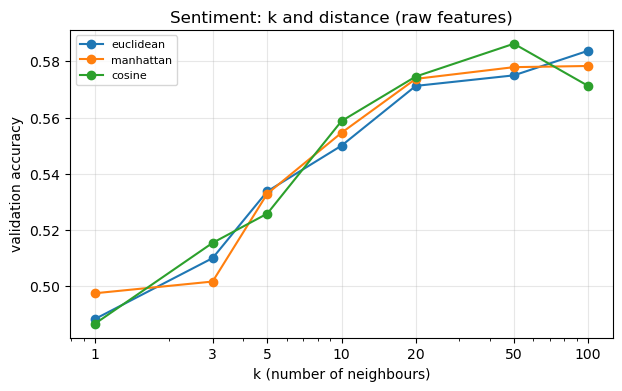

In [14]:
SENT_KS = [1, 3, 5, 10, 20, 50, 100]

curves = {}
for distance in ["euclidean", "manhattan", "cosine"]:
    curves[distance] = try_settings("sentiment", X_sent, y_sent, "none", distance, SENT_KS)
plot_k_curves(SENT_KS, curves, "Sentiment: k and distance (raw features)")

### 6.2 Effect of normalisation

none, euclidean, uniform                 k=1: 0.488  k=3: 0.510  k=5: 0.534  k=10: 0.550  k=20: 0.571  k=50: 0.575  k=100: 0.584
none, cosine, uniform                    k=1: 0.487  k=3: 0.515  k=5: 0.526  k=10: 0.559  k=20: 0.575  k=50: 0.586  k=100: 0.571
standardize, euclidean, uniform          k=1: 0.490  k=3: 0.512  k=5: 0.535  k=10: 0.548  k=20: 0.579  k=50: 0.581  k=100: 0.581
standardize, cosine, uniform             k=1: 0.488  k=3: 0.516  k=5: 0.543  k=10: 0.559  k=20: 0.571  k=50: 0.586  k=100: 0.586


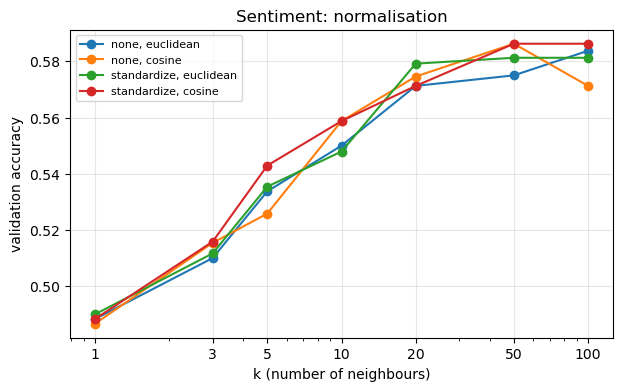

In [15]:
curves = {}
for preprocess in ["none", "standardize"]:
    for distance in ["euclidean", "cosine"]:
        curves[f"{preprocess}, {distance}"] = try_settings("sentiment", X_sent, y_sent,
                                                           preprocess, distance, SENT_KS)
plot_k_curves(SENT_KS, curves, "Sentiment: normalisation")

### 6.3 Uniform vs distance-weighted voting

standardize, cosine, uniform             k=1: 0.488  k=3: 0.516  k=5: 0.543  k=10: 0.559  k=20: 0.571  k=50: 0.586  k=100: 0.586
standardize, cosine, 1/d^1               k=1: 0.488  k=3: 0.516  k=5: 0.541  k=10: 0.558  k=20: 0.572  k=50: 0.589  k=100: 0.586
standardize, cosine, 1/d^2               k=1: 0.488  k=3: 0.516  k=5: 0.539  k=10: 0.562  k=20: 0.572  k=50: 0.591  k=100: 0.591
standardize, cosine, 1/d^4               k=1: 0.488  k=3: 0.516  k=5: 0.537  k=10: 0.557  k=20: 0.579  k=50: 0.594  k=100: 0.600
standardize, cosine, 1/d^8               k=1: 0.488  k=3: 0.510  k=5: 0.528  k=10: 0.548  k=20: 0.570  k=50: 0.585  k=100: 0.588


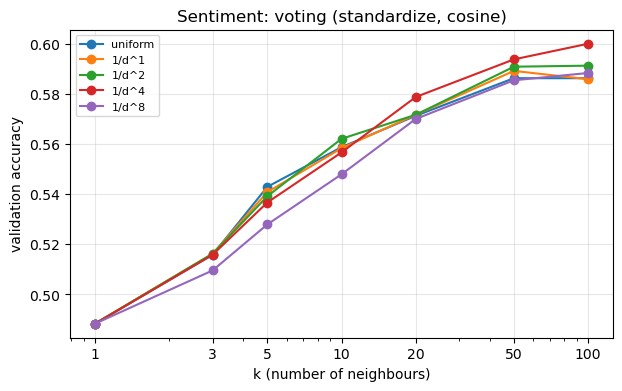

In [16]:
SENT_PREPROCESS = "standardize"
SENT_DISTANCE = "cosine"

curves = {"uniform": try_settings("sentiment", X_sent, y_sent, SENT_PREPROCESS, SENT_DISTANCE, SENT_KS)}
for power in [1, 2, 4, 8]:
    curves[f"1/d^{power}"] = try_settings("sentiment", X_sent, y_sent, SENT_PREPROCESS, SENT_DISTANCE,
                                         SENT_KS, weighting="distance", power=power)
plot_k_curves(SENT_KS, curves, f"Sentiment: voting ({SENT_PREPROCESS}, {SENT_DISTANCE})")

pd.DataFrame([r for r in all_results if r["task"] == "sentiment"]).to_csv(
    "results/knn/sentiment_experiments.csv", index=False)

### 6.4 Training vs validation accuracy

k =   1   train 1.000   validation 0.488
k =   3   train 0.750   validation 0.516
k =   5   train 0.689   validation 0.543
k =  10   train 0.661   validation 0.559
k =  20   train 0.631   validation 0.571
k =  50   train 0.612   validation 0.586
k = 100   train 0.603   validation 0.586


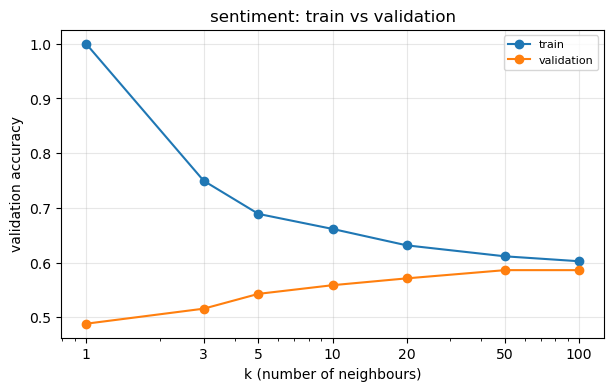

In [17]:
train_vs_validation("sentiment", X_sent, y_sent, SENT_PREPROCESS, SENT_DISTANCE, SENT_KS)

### Best settings found so far

The full tables are in `results/knn/`. The 10 best settings per task:

In [18]:
results_table = pd.DataFrame(all_results)
for task in ["image", "sentiment"]:
    print(task)
    display(results_table[results_table["task"] == task]
            .sort_values("val_acc", ascending=False).head(10))

image


,task,preprocess,distance,weighting,k,val_acc,neighbour_search_seconds
80,image,sqrt,cosine,1/d^8,5,0.5693,18.8
79,image,sqrt,cosine,1/d^8,3,0.5670,18.8
81,image,sqrt,cosine,1/d^8,10,0.5635,18.8
42,image,sqrt,euclidean,uniform,1,0.5630,16.9
48,image,sqrt,cosine,uniform,1,0.5627,18.8
78,image,sqrt,cosine,1/d^8,1,0.5627,18.8
72,image,sqrt,cosine,1/d^4,1,0.5627,18.8
66,image,sqrt,cosine,1/d^2,1,0.5627,18.8
60,image,sqrt,cosine,1/d^1,1,0.5627,18.8
54,image,sqrt,cosine,uniform,1,0.5627,18.8


sentiment


,task,preprocess,distance,weighting,k,val_acc,neighbour_search_seconds
160,sentiment,standardize,cosine,1/d^4,100,0.6000,6.8
159,sentiment,standardize,cosine,1/d^4,50,0.5938,6.8
153,sentiment,standardize,cosine,1/d^2,100,0.5913,6.8
152,sentiment,standardize,cosine,1/d^2,50,0.5908,6.8
145,sentiment,standardize,cosine,1/d^1,50,0.5892,6.8
167,sentiment,standardize,cosine,1/d^8,100,0.5883,6.8
132,sentiment,standardize,cosine,uniform,100,0.5863,6.8
117,sentiment,none,cosine,uniform,50,0.5863,5.5
131,sentiment,standardize,cosine,uniform,50,0.5863,6.8
138,sentiment,standardize,cosine,uniform,50,0.5863,6.8


## 7. Best models – error analysis

**Write the best settings from the tables above here**, then run this section.

In [19]:
BEST_IMAGE = {"preprocess": "sqrt", "distance": "cosine", "k": 1, "weighting": "uniform", "power": 1}
BEST_SENT = {"preprocess": "standardize", "distance": "cosine", "k": 50, "weighting": "uniform", "power": 1}


def validation_predictions(task, X, y, best):
    X_tr, y_tr, X_va, y_va = prepare(X, y, best["preprocess"])
    knn = KNNClassifier(best["k"], best["distance"], best["weighting"], best["power"]).fit(X_tr, y_tr)
    start = time.time()
    y_pred = knn.predict(X_va)
    print(f"{task}: validation accuracy {common.accuracy(y_va, y_pred):.4f}"
          f"   (prediction time {time.time() - start:.1f}s for {len(X_va)} examples)")
    np.save(f"results/knn/{task}_val_pred.npy", y_pred)   # to compare mistakes with other models
    return y_va, y_pred


def plot_confusion(cm, title, labels=None):
    normalized = cm / cm.sum(axis=1, keepdims=True)
    size = 5 if len(cm) <= 3 else 10
    plt.figure(figsize=(size, size * 0.85))
    plt.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar()
    if labels is not None:
        plt.xticks(range(len(labels)), labels)
        plt.yticks(range(len(labels)), labels)
        for i in range(len(cm)):
            for j in range(len(cm)):
                plt.text(j, i, f"{cm[i, j]}\n{normalized[i, j]:.0%}", ha="center", va="center",
                         color="white" if normalized[i, j] > 0.5 else "black")
    plt.xlabel("predicted class")
    plt.ylabel("true class")
    plt.title(title)
    plt.show()

### 7.1 Sentiment

sentiment: validation accuracy 0.5863   (prediction time 8.1s for 2400 examples)


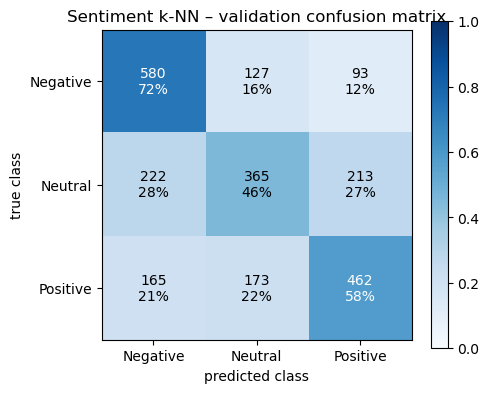

Negative  recall 0.725   precision 0.600
Neutral   recall 0.456   precision 0.549
Positive  recall 0.578   precision 0.602


In [20]:
y_va, y_pred = validation_predictions("sentiment", X_sent, y_sent, BEST_SENT)
cm = common.confusion_matrix(y_va, y_pred, 3)
plot_confusion(cm, "Sentiment k-NN – validation confusion matrix", common.SENTIMENT_NAMES)
recall = common.per_class_recall(cm)
precision = common.per_class_precision(cm)
for i, name in enumerate(common.SENTIMENT_NAMES):
    print(f"{name:<9} recall {recall[i]:.3f}   precision {precision[i]:.3f}")

### 7.2 Image

image: validation accuracy 0.5627   (prediction time 16.1s for 4000 examples)


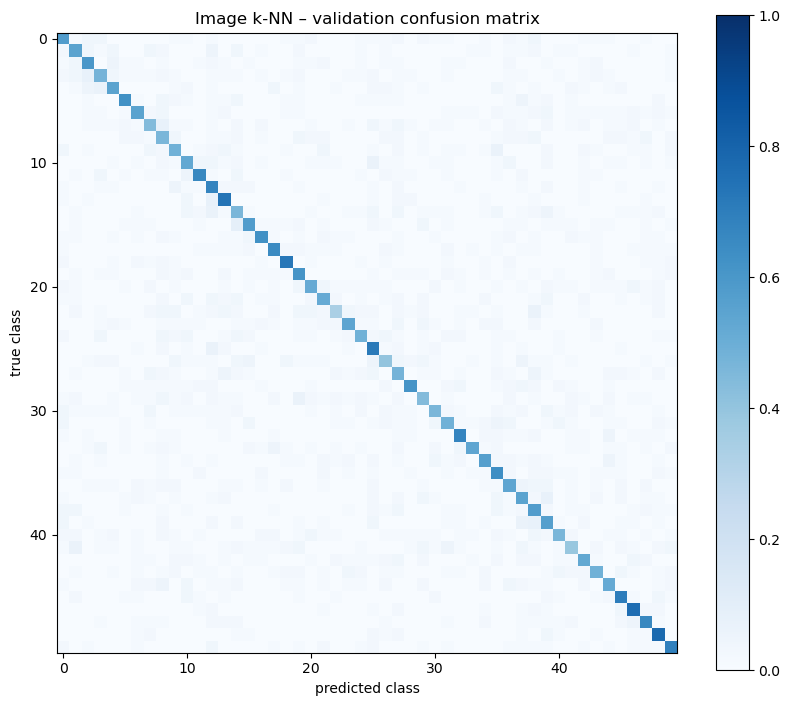

5 hardest classes: [(22, 0.34), (41, 0.39), (26, 0.4), (29, 0.44), (7, 0.44)]
5 easiest classes: [(25, 0.71), (18, 0.72), (13, 0.74), (46, 0.76), (48, 0.78)]

Most frequent mistakes (true class -> predicted class):
  15 -> 14   7 times
   3 ->  2   6 times
   7 ->  8   6 times
  13 -> 12   6 times
  37 -> 39   6 times
  39 -> 38   6 times
   4 ->  3   5 times
   9 -> 35   5 times
  10 -> 25   5 times
  14 -> 12   5 times


In [21]:
y_va, y_pred = validation_predictions("image", X_image, y_image, BEST_IMAGE)
cm = common.confusion_matrix(y_va, y_pred, 50)
plot_confusion(cm, "Image k-NN – validation confusion matrix")
recall = common.per_class_recall(cm)
order = np.argsort(recall)
print("5 hardest classes:", [(int(c), round(float(recall[c]), 2)) for c in order[:5]])
print("5 easiest classes:", [(int(c), round(float(recall[c]), 2)) for c in order[-5:]])
print("\nMost frequent mistakes (true class -> predicted class):")
for true_c, pred_c, count in common.most_confused_pairs(cm, 10):
    print(f"  {true_c:2d} -> {pred_c:2d}   {count} times")

## 8. Final predictions on the test set

The final k-NN simply stores **all** the training data (train + validation) and predicts the test set.

Files written:

* `predictions/knn_image_test.csv`, `predictions/knn_sentiment_test.csv` – one file per task
* `predictions/submission_knn.csv` – k-NN for both tasks
* `predictions/submission_knn_image_nn_sentiment.csv` – k-NN for images + neural network for sentiment, if the NN notebook has already written `predictions/nn_sentiment_test.csv`

In [22]:
def predict_test(X, y, X_test, best):
    stats = common.fit_preprocessing(X, best["preprocess"])           # all training rows
    X_all = common.apply_preprocessing(X, best["preprocess"], stats)
    X_test = common.apply_preprocessing(X_test, best["preprocess"], stats)
    knn = KNNClassifier(best["k"], best["distance"], best["weighting"], best["power"]).fit(X_all, y)
    return knn.predict(X_test)


image_pred = predict_test(X_image, y_image, X_image_test, BEST_IMAGE)
sent_pred = predict_test(X_sent, y_sent, X_sent_test, BEST_SENT)

pd.DataFrame({"id": image_test_ids, "label": image_pred}).to_csv("predictions/knn_image_test.csv", index=False)
pd.DataFrame({"id": sent_test_ids, "label": sent_pred}).to_csv("predictions/knn_sentiment_test.csv", index=False)
common.make_submission(image_test_ids, image_pred, sent_test_ids, sent_pred, "predictions/submission_knn.csv")
print("written: predictions/submission_knn.csv")

if os.path.exists("predictions/nn_sentiment_test.csv"):
    nn_sent = pd.read_csv("predictions/nn_sentiment_test.csv")
    common.make_submission(image_test_ids, image_pred, nn_sent["id"], nn_sent["label"],
                           "predictions/submission_knn_image_nn_sentiment.csv")
    print("written: predictions/submission_knn_image_nn_sentiment.csv")
else:
    print("no NN sentiment predictions yet (run the NN notebook first for the combined file)")

written: predictions/submission_knn.csv
no NN sentiment predictions yet (run the NN notebook first for the combined file)
